In [25]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
import time

# Reload completed Kalshi datasets
kalshi_df = pd.read_csv(
    "../data/kalshi_48h.csv",
    low_memory=False
)

kalshi_clean = pd.read_csv(
    "../data/kalshi_clean.csv",
    low_memory=False
)

# Recreate category_counts in case later cells use it
category_counts = kalshi_df["category"].value_counts()

poly_48h = pd.read_csv(
    "../data/polymarket_48h.csv",
    dtype={"market_id": str},
    low_memory=False
)

poly_48h["resolution_date"] = pd.to_datetime(
    poly_48h["resolution_date"],
    format="mixed",
    utc=True,
    errors="coerce"
)

poly_clean = poly_48h[
    [
        "market_id",
        "resolution_date",
        "price_48h",
        "outcome"
    ]
].copy()

poly_clean["venue"] = "Polymarket"

poly_clean = poly_clean.rename(
    columns={
        "market_id": "market",
        "price_48h": "price"
    }
)

kalshi_final = kalshi_clean[
    [
        "ticker",
        "category",
        "resolution_date",
        "mid_price_48h",
        "outcome"
    ]
].copy()

kalshi_final["venue"] = "Kalshi"

kalshi_final = kalshi_final.rename(
    columns={
        "ticker": "market",
        "mid_price_48h": "price"
    }
)

print("Polymarket rows:", len(poly_clean))
print("Kalshi rows:", len(kalshi_final))

Polymarket rows: 62005
Kalshi rows: 22825


In [22]:

# Load the raw Kalshi markets we already saved
df = pd.read_csv(
    "../data/kalshi_raw_markets.csv",
    low_memory=False
)

# Convert timestamps
df["event_time"] = pd.to_datetime(
    df["occurrence_datetime"],
    format="mixed",
    utc=True
)

df["open_time"] = pd.to_datetime(
    df["open_time"],
    format="mixed",
    utc=True
)

# 48 hours before the event
df["target_time"] = df["event_time"] - pd.Timedelta(hours=48)

now = pd.Timestamp.now(tz="UTC")

# Keep markets that were already open at the 48-hour point
eligible_df = df[
    (df["open_time"] <= df["target_time"]) &
    (df["target_time"] <= now)
].copy()

print("Total markets:", len(df))
print("Eligible markets:", len(eligible_df))

Total markets: 386069
Eligible markets: 24099


In [ ]:
# The reason why I grouped the same target-time markets together is because that it tooks forever to run if I call API individually using a method. 
BATCH_URL = (
    "https://external-api.kalshi.com/trade-api/v2/"
    "markets/candlesticks"
)

kalshi_results = []
event_cache = {}

# Group markets by their exact 48-hour target time
groups = eligible_df.groupby("target_time")

total_groups = len(groups)
groups_done = 0

for target_time, group in groups:

    # Kalshi allows max 100 tickers per batch
    for start in range(0, len(group), 100):

        batch = group.iloc[start:start + 100]
        tickers = batch["ticker"].tolist()

        start_ts = int(
            (target_time - pd.Timedelta(minutes=5)).timestamp()
        )

        end_ts = int(target_time.timestamp())

        params = {
            "market_tickers": ",".join(tickers),
            "start_ts": start_ts,
            "end_ts": end_ts,
            "period_interval": 1,
            "include_latest_before_start": True
        }

        # Get batch candlesticks
        while True:

            response = requests.get(
                BATCH_URL,
                params=params
            )

            if response.status_code == 429:
                print("Rate limited. Waiting 5 seconds...")
                time.sleep(5)
                continue

            response.raise_for_status()
            break

        batch_data = response.json()

        # Make ticker -> candles dictionary
        candle_lookup = {}

        for item in batch_data["markets"]:
            candle_lookup[item["market_ticker"]] = item["candlesticks"]

        # Process each market
        for _, market in batch.iterrows():

            ticker = market["ticker"]

            candles = candle_lookup.get(ticker, [])

            if not candles:
                continue

            # Only candles at or before the 48h target
            valid_candles = [
                candle for candle in candles
                if pd.to_datetime(
                    candle["end_period_ts"],
                    unit="s",
                    utc=True
                ) <= target_time
            ]

            if not valid_candles:
                continue

            # Latest available candle before target
            candle = max(
                valid_candles,
                key=lambda x: x["end_period_ts"]
            )

            # Need bid and ask for midpoint
            if not candle.get("yes_bid") or not candle.get("yes_ask"):
                continue

            if (
                candle["yes_bid"].get("close_dollars") is None
                or candle["yes_ask"].get("close_dollars") is None
            ):
                continue

            bid = float(
                candle["yes_bid"]["close_dollars"]
            )

            ask = float(
                candle["yes_ask"]["close_dollars"]
            )

            mid_price = (bid + ask) / 2

            # Get category
            event_ticker = market["event_ticker"]

            if event_ticker in event_cache:

                category = event_cache[event_ticker]

            else:

                event_url = (
                    "https://external-api.kalshi.com/"
                    "trade-api/v2/events/"
                    f"{event_ticker}"
                )

                while True:

                    event_response = requests.get(event_url)

                    if event_response.status_code == 429:
                        print("Rate limited. Waiting 5 seconds...")
                        time.sleep(5)
                        continue

                    event_response.raise_for_status()
                    break

                event_data = event_response.json()

                category = event_data["event"]["category"]

                event_cache[event_ticker] = category

       
            # Outcome
            result = str(market["result"]).lower()

            if result == "yes":
                outcome = 1

            elif result == "no":
                outcome = 0

            else:
                continue

         
            # Save row
            kalshi_results.append({
                "ticker": ticker,
                "category": category,
                "resolution_date": market["expected_expiration_time"],
                "mid_price_48h": mid_price,
                "outcome": outcome
            })

    groups_done += 1

    # Progress report
    if groups_done % 50 == 0:

        print(
            f"Groups processed: {groups_done} / {total_groups}"
            f" | Rows collected: {len(kalshi_results)}"
        )

        pd.DataFrame(kalshi_results).to_csv(
            "../data/kalshi_progress.csv",
            index=False
        )

# Final dataframe
kalshi_df = pd.DataFrame(kalshi_results)

kalshi_df.to_csv(
    "../data/kalshi_48h.csv",
    index=False
)

print("\nDONE")
print("Eligible markets:", len(eligible_df))
print("Rows collected:", len(kalshi_df))

kalshi_df.head()

In [ ]:
# Keep only categories with at least 100 markets

valid_categories = category_counts[
    category_counts >= 100
].index

kalshi_clean = kalshi_df[
    kalshi_df["category"].isin(valid_categories)
].copy()

print("Before cleaning:", len(kalshi_df))
print("After cleaning:", len(kalshi_clean))

print("\nCategories remaining:")
print(kalshi_clean["category"].value_counts().to_string())

# Save cleaned Kalshi dataset
kalshi_clean.to_csv(
    "../data/kalshi_clean.csv",
    index=False
)

print("Saved:", len(kalshi_clean), "Kalshi markets")

In [ ]:
polymarket_url = "https://gamma-api.polymarket.com/markets/keyset"
all_poly_markets = []
cursor = None

while True:

    params = {
        "closed": "true",
        "limit": 100
    }

    if cursor:
        params["after_cursor"] = cursor

    while True:

        response = requests.get(
            polymarket_url,
            params=params
        )

        if response.status_code == 429:
            print("Rate limited. Waiting 5 seconds...")
            time.sleep(5)
            continue

        response.raise_for_status()
        break

    data = response.json()
    markets = data["markets"]
    all_poly_markets.extend(markets)
    print("Markets downloaded:", len(all_poly_markets))
    cursor = data.get("next_cursor")

    if not cursor:
        break

    time.sleep(0.05)

poly_raw = pd.DataFrame(all_poly_markets)

poly_raw.to_json(
    "../data/polymarket_raw_markets.json",
    orient="records"
)

print("\nDONE")
print("Total closed markets:", len(poly_raw))
poly_raw.head()

In [ ]:
# Rebuild Polymarket DataFrame from downloaded raw markets
poly_raw = pd.DataFrame(all_poly_markets)

# Convert timestamp columns to real datetimes
poly_raw["endDate"] = pd.to_datetime(
    poly_raw["endDate"],
    utc=True,
    errors="coerce"
)

poly_raw["closedTime"] = pd.to_datetime(
    poly_raw["closedTime"],
    utc=True,
    errors="coerce"
)

poly_raw["createdAt"] = pd.to_datetime(
    poly_raw["createdAt"],
    utc=True,
    errors="coerce"
)

# Difference between scheduled end time and actual close time
poly_raw["time_gap"] = (
    poly_raw["closedTime"] - poly_raw["endDate"]
)

# Keep markets where endDate and closedTime are within 1 day
poly_time_clean = poly_raw[
    poly_raw["time_gap"].abs() <= pd.Timedelta(days=1)
].copy()

# Define the 48-hour pre-event target time
poly_time_clean["target_time"] = (
    poly_time_clean["endDate"] - pd.Timedelta(hours=48)
)

# Save the raw partial dataset
poly_raw.to_json(
    "../data/polymarket_raw_partial.json",
    orient="records"
)

print("Raw markets:", len(poly_raw))
print("After timestamp filter:", len(poly_time_clean))

print("\nTarget time example:")
print(
    poly_time_clean[
        ["question", "endDate", "closedTime", "target_time"]
    ].head()
)


In [ ]:
import json

def parse_list(value):
    if isinstance(value, list):
        return value

    if isinstance(value, str):
        try:
            return json.loads(value)
        except:
            return None

    return None


poly_binary = poly_time_clean.copy()

# Parse list-like fields
poly_binary["parsed_outcomes"] = (
    poly_binary["outcomes"].apply(parse_list)
)

poly_binary["parsed_prices"] = (
    poly_binary["outcomePrices"].apply(parse_list)
)

poly_binary["parsed_tokens"] = (
    poly_binary["clobTokenIds"].apply(parse_list)
)


# Must have exactly 2 outcomes, prices, and tokens
poly_binary = poly_binary[
    poly_binary["parsed_outcomes"].apply(
        lambda x: isinstance(x, list) and len(x) == 2
    )
    &
    poly_binary["parsed_prices"].apply(
        lambda x: isinstance(x, list) and len(x) == 2
    )
    &
    poly_binary["parsed_tokens"].apply(
        lambda x: isinstance(x, list) and len(x) == 2
    )
].copy()


# Convert both final prices to numbers
poly_binary["final_price_1"] = pd.to_numeric(
    poly_binary["parsed_prices"].apply(lambda x: x[0]),
    errors="coerce"
)

poly_binary["final_price_2"] = pd.to_numeric(
    poly_binary["parsed_prices"].apply(lambda x: x[1]),
    errors="coerce"
)


# Keep only clean binary resolutions:
# [1, 0] or [0, 1]
poly_binary = poly_binary[
    (
        (poly_binary["final_price_1"] == 1) &
        (poly_binary["final_price_2"] == 0)
    )
    |
    (
        (poly_binary["final_price_1"] == 0) &
        (poly_binary["final_price_2"] == 1)
    )
].copy()


# First listed outcome won = 1, lost = 0
poly_binary["outcome"] = (
    poly_binary["final_price_1"].astype(int)
)


# Token for the first listed outcome
poly_binary["token_id"] = (
    poly_binary["parsed_tokens"].apply(lambda x: x[0])
)


# Market must already exist at T - 48h
poly_binary = poly_binary[
    poly_binary["createdAt"] <= poly_binary["target_time"]
].copy()


print("Timestamp-clean markets:", len(poly_time_clean))
print("Usable binary markets:", len(poly_binary))

print("\nOutcome counts:")
print(poly_binary["outcome"].value_counts())

print("\nFinal resolution combinations:")
print(
    poly_binary[
        ["final_price_1", "final_price_2"]
    ].value_counts()
)

print("\nExamples:")
print(
    poly_binary[
        [
            "question",
            "parsed_outcomes",
            "parsed_prices",
            "outcome"
        ]
    ].head(10)
)

In [38]:
poly_binary.to_json(
    "../data/polymarket_binary.json",
    orient="records"
)

print("Saved usable markets:", len(poly_binary))

C:\Users\JianT\AppData\Local\Temp\ipykernel_21888\2487563329.py:1: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  poly_binary.to_json(


Saved usable markets: 63507


In [28]:
poly_binary = pd.read_json(
    "../data/polymarket_binary.json",
    orient="records",
    dtype={
        "token_id": "string",
        "id": "string"
    },
    convert_dates=False
)

for col in ["endDate", "closedTime", "createdAt", "target_time"]:
    if col in poly_binary.columns:
        poly_binary[col] = pd.to_datetime(
            poly_binary[col],
            unit="ms",
            utc=True,
            errors="coerce"
        )

print("Markets:", len(poly_binary))

print(
    poly_binary[
        ["endDate", "closedTime", "createdAt", "target_time"]
    ].head()
)

Markets: 63507
                    endDate                closedTime  \
0 2023-04-01 00:00:00+00:00 2023-04-01 13:21:34+00:00   
1 2023-03-13 00:00:00+00:00 2023-03-13 05:48:35+00:00   
2 2023-03-13 00:00:00+00:00 2023-03-13 05:48:19+00:00   
3 2023-03-13 00:00:00+00:00 2023-03-13 05:48:57+00:00   
4 2023-05-31 00:00:00+00:00 2023-05-31 18:48:40+00:00   

                         createdAt               target_time  
0 2023-01-09 21:12:47.070000+00:00 2023-03-30 00:00:00+00:00  
1 2023-01-13 22:14:31.280000+00:00 2023-03-11 00:00:00+00:00  
2 2023-01-13 22:18:20.196000+00:00 2023-03-11 00:00:00+00:00  
3 2023-01-14 01:50:27.026000+00:00 2023-03-11 00:00:00+00:00  
4 2023-01-20 22:36:31.605000+00:00 2023-05-29 00:00:00+00:00  


In [ ]:
BATCH_PRICE_URL = (
    "https://clob.polymarket.com/batch-prices-history"
)

poly_results = []

# Markets with the same T-48h target can share one request window
groups = poly_binary.groupby("target_time")

total_groups = len(groups)
groups_done = 0

session = requests.Session()

for target_time, group in groups:

    # Polymarket allows max 20 token IDs per batch
    for start in range(0, len(group), 20):

        batch = group.iloc[start:start + 20]

        token_ids = (
            batch["token_id"]
            .astype(str)
            .tolist()
        )

        # Search the hour immediately before T-48h
        start_ts = int(
            (target_time - pd.Timedelta(hours=1)).timestamp()
        )

        end_ts = int(
            target_time.timestamp()
        )

        payload = {
            "markets": token_ids,
            "start_ts": start_ts,
            "end_ts": end_ts,
            "fidelity": 1
        }

        while True:

            try:
                response = session.post(
                    BATCH_PRICE_URL,
                    json=payload,
                    timeout=30
                )

            except requests.exceptions.Timeout:
                print("Timed out. Retrying...")
                continue

            if response.status_code == 429:
                print("Rate limited. Waiting 5 seconds...")
                time.sleep(5)
                continue

            response.raise_for_status()
            break

        batch_data = response.json()

        history_lookup = batch_data.get(
            "history",
            {}
        )

        # Process each market in the batch
        for _, market in batch.iterrows():

            token_id = str(market["token_id"])

            history = history_lookup.get(
                token_id,
                []
            )

            if not history:
                continue

            # Never use information after T-48h
            valid_points = [
                point
                for point in history
                if pd.to_datetime(
                    point["t"],
                    unit="s",
                    utc=True
                ) <= target_time
            ]

            if not valid_points:
                continue

            # Closest historical point at or before T-48h
            latest_point = max(
                valid_points,
                key=lambda x: x["t"]
            )

            price_48h = float(
                latest_point["p"]
            )

            price_time = pd.to_datetime(
                latest_point["t"],
                unit="s",
                utc=True
            )

            staleness_seconds = (
                target_time - price_time
            ).total_seconds()

            poly_results.append({
                "market_id": market["id"],
                "question": market["question"],
                "resolution_date": market["endDate"],
                "target_time": target_time,
                "price_time": price_time,
                "price_48h": price_48h,
                "staleness_seconds": staleness_seconds,
                "outcome": market["outcome"],
                "token_id": token_id
            })


    groups_done += 1

    # Progress checkpoint
    if groups_done % 100 == 0:

        print(
            f"Groups processed: {groups_done} / {total_groups}"
            f" | Rows collected: {len(poly_results)}"
        )

        pd.DataFrame(poly_results).to_csv(
            "../data/polymarket_progress.csv",
            index=False
        )


# Final dataframe
poly_48h = pd.DataFrame(poly_results)

poly_48h.to_csv(
    "../data/polymarket_48h.csv",
    index=False
)

print("\nDONE")
print("Eligible binary markets:", len(poly_binary))
print("Rows collected:", len(poly_48h))

poly_48h.head()

In [ ]:
# Make sure these are datetimes
poly_48h["target_time"] = pd.to_datetime(
    poly_48h["target_time"],
    utc=True
)

poly_48h["price_time"] = pd.to_datetime(
    poly_48h["price_time"],
    utc=True
)

# Correct resolution/event date
poly_48h["resolution_date"] = (
    poly_48h["target_time"] + pd.Timedelta(hours=48)
)

# Save corrected dataset
poly_48h.to_csv(
    "../data/polymarket_48h.csv",
    index=False
)

print(
    poly_48h[
        [
            "question",
            "resolution_date",
            "target_time",
            "price_time",
            "price_48h",
            "outcome"
        ]
    ].head()
)

In [10]:
## Making two datasets structually identical

poly_clean = poly_48h[
    [
        "market_id",
        "resolution_date",
        "price_48h",
        "outcome"
    ]
].copy()

poly_clean["venue"] = "Polymarket"

poly_clean = poly_clean.rename(
    columns={
        "market_id": "market",
        "price_48h": "price"
    }
)

kalshi_final = kalshi_clean[
    [
        "ticker",
        "category",
        "resolution_date",
        "mid_price_48h",
        "outcome"
    ]
].copy()

kalshi_final["venue"] = "Kalshi"

kalshi_final = kalshi_final.rename(
    columns={
        "ticker": "market",
        "mid_price_48h": "price"
    }
)

In [29]:
import re

def get_poly_text(row):
    parts = [str(row.get("question", ""))]

    events = row.get("events", [])

    if isinstance(events, list):
        for event in events:
            if isinstance(event, dict):
                parts.append(str(event.get("title", "")))
                parts.append(str(event.get("slug", "")))
                parts.append(str(event.get("description", "")))

    return " ".join(parts).lower()


def contains_term(text, term):
    return re.search(
        rf"(?<!\w){re.escape(term)}(?!\w)",
        text
    ) is not None


def assign_category(text):

    sports_words = [
        "nba", "nfl", "mlb", "nhl", "soccer", "football",
        "basketball", "baseball", "tennis", "ufc", "boxing",
        "champions league", "premier league", "world cup",
        "super bowl", "game", "match"
    ]

    politics_words = [
        "president", "election", "trump", "biden",
        "congress", "senate", "governor", "prime minister",
        "parliament", "democrat", "republican"
    ]

    crypto_words = [
        "bitcoin", "btc", "ethereum", "eth",
        "crypto", "solana", "xrp", "token"
    ]

    economics_words = [
        "fed", "interest rate", "inflation", "gdp",
        "unemployment", "recession", "stock",
        "s&p", "nasdaq", "dow", "market cap"
    ]

    entertainment_words = [
        "oscar", "grammy", "movie", "film",
        "album", "song", "actor", "actress",
        "emmy", "box office"
    ]

    tech_words = [
        "ai", "artificial intelligence", "spacex",
        "openai", "apple", "google", "microsoft",
        "launch", "space"
    ]

    climate_words = [
        "temperature", "weather", "hurricane",
        "climate", "snow", "rain", "storm"
    ]

    if any(contains_term(text, word) for word in sports_words):
        return "Sports"

    if any(contains_term(text, word) for word in politics_words):
        return "Politics"

    if any(contains_term(text, word) for word in crypto_words):
        return "Crypto"

    if any(contains_term(text, word) for word in economics_words):
        return "Economics/Finance"

    if any(contains_term(text, word) for word in entertainment_words):
        return "Entertainment"

    if any(contains_term(text, word) for word in tech_words):
        return "Science/Technology"

    if any(contains_term(text, word) for word in climate_words):
        return "Climate/Weather"

    return "Other"

In [30]:
poly_binary["category_text"] = poly_binary.apply(
    get_poly_text,
    axis=1
)

poly_binary["category"] = (
    poly_binary["category_text"].apply(assign_category)
)

In [31]:
category_lookup = poly_binary[
    ["id", "category"]
].copy()

# Normalize IDs on BOTH sides
category_lookup["id"] = (
    category_lookup["id"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

poly_clean["market"] = (
    poly_clean["market"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

poly_clean = poly_clean.merge(
    category_lookup,
    left_on="market",
    right_on="id",
    how="left"
)

poly_clean = poly_clean.drop(
    columns=["id"]
)

print(poly_clean["category"].value_counts())

print("\nMissing categories:")
print(poly_clean["category"].isna().sum())

category
Crypto                22576
Sports                22455
Other                  8666
Politics               3198
Climate/Weather        2232
Entertainment          1132
Economics/Finance      1110
Science/Technology      636
Name: count, dtype: int64

Missing categories:
0


In [33]:
kalshi_final["category"] = kalshi_final["category"].replace({
    "Financials": "Economics/Finance",
    "Economics": "Economics/Finance",
    "Climate and Weather": "Climate/Weather",
    "Science and Technology": "Science/Technology",
    "Mentions": "Other"
})
# Make sure column order matches
kalshi_final = kalshi_final[
    ["market", "category", "resolution_date", "price", "outcome", "venue"]
]

poly_clean = poly_clean[
    ["market", "category", "resolution_date", "price", "outcome", "venue"]
]

# Combine both venues
combined = pd.concat(
    [kalshi_final, poly_clean],
    ignore_index=True
)

print("Combined rows:", len(combined))

print("\nBy venue:")
print(combined["venue"].value_counts())

print("\nBy category:")
print(combined["category"].value_counts())

category_counts = combined["category"].value_counts()

valid_categories = category_counts[
    category_counts >= 100
].index

combined_clean = combined[
    combined["category"].isin(valid_categories)
].copy()

print("Before category filter:", len(combined))
print("After category filter:", len(combined_clean))

print("\nFinal categories:")
print(combined_clean["category"].value_counts())

Combined rows: 84830

By venue:
venue
Polymarket    62005
Kalshi        22825
Name: count, dtype: int64

By category:
category
Sports                41084
Crypto                22576
Other                  8786
Economics/Finance      4593
Politics               3198
Climate/Weather        2363
Entertainment          1334
Science/Technology      656
Commodities             240
Name: count, dtype: int64
Before category filter: 84830
After category filter: 84830

Final categories:
category
Sports                41084
Crypto                22576
Other                  8786
Economics/Finance      4593
Politics               3198
Climate/Weather        2363
Entertainment          1334
Science/Technology      656
Commodities             240
Name: count, dtype: int64


In [34]:
# ============================================================
# FINAL DATASET FIX
# ============================================================

# combined_clean already exists from the combine cell above.
# Do NOT reload prediction_markets_clean.csv here.

combined_clean["market"] = (
    combined_clean["market"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

combined_clean["resolution_date"] = pd.to_datetime(
    combined_clean["resolution_date"],
    format="mixed",
    utc=True,
    errors="coerce"
)


# ============================================================
# KALSHI: ENTRY TIME + ACTUAL SETTLEMENT
# ============================================================

kalshi_meta = pd.read_csv(
    "../data/kalshi_raw_markets.csv",
    usecols=[
        "ticker",
        "occurrence_datetime",
        "settlement_ts"
    ],
    dtype={"ticker": str},
    low_memory=False
)

kalshi_meta["ticker"] = (
    kalshi_meta["ticker"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

kalshi_meta["entry_time"] = (
    pd.to_datetime(
        kalshi_meta["occurrence_datetime"],
        format="mixed",
        utc=True,
        errors="coerce"
    )
    - pd.Timedelta(hours=48)
)

kalshi_meta["actual_resolution"] = pd.to_datetime(
    kalshi_meta["settlement_ts"],
    format="mixed",
    utc=True,
    errors="coerce"
)

kalshi_lookup = (
    kalshi_meta[
        [
            "ticker",
            "entry_time",
            "actual_resolution"
        ]
    ]
    .drop_duplicates("ticker")
    .rename(columns={"ticker": "market"})
)

kalshi_lookup["venue"] = "Kalshi"


# ============================================================
# POLYMARKET: ENTRY TIME + ACTUAL CLOSE
# ============================================================

poly_time = poly_48h[
    ["market_id", "target_time"]
].copy()

poly_time["market_id"] = (
    poly_time["market_id"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

poly_time["entry_time"] = pd.to_datetime(
    poly_time["target_time"],
    format="mixed",
    utc=True,
    errors="coerce"
)

# poly_binary already has correctly parsed closedTime from the cell
# you just fixed.
poly_resolution = poly_binary[
    ["id", "closedTime"]
].copy()

poly_resolution["id"] = (
    poly_resolution["id"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

poly_resolution = (
    poly_resolution
    .drop_duplicates("id")
    .rename(
        columns={
            "id": "market",
            "closedTime": "actual_resolution"
        }
    )
)

poly_time = (
    poly_time[
        ["market_id", "entry_time"]
    ]
    .drop_duplicates("market_id")
    .rename(columns={"market_id": "market"})
)

poly_lookup = poly_time.merge(
    poly_resolution,
    on="market",
    how="left"
)

poly_lookup["venue"] = "Polymarket"


# ============================================================
# COMBINE TIME LOOKUPS
# ============================================================

time_lookup = pd.concat(
    [
        kalshi_lookup[
            [
                "market",
                "venue",
                "entry_time",
                "actual_resolution"
            ]
        ],
        poly_lookup[
            [
                "market",
                "venue",
                "entry_time",
                "actual_resolution"
            ]
        ]
    ],
    ignore_index=True
)

# Remove old versions before merging
combined_clean = combined_clean.drop(
    columns=[
        "entry_time",
        "actual_resolution"
    ],
    errors="ignore"
)

combined_clean = combined_clean.merge(
    time_lookup,
    on=["market", "venue"],
    how="left"
)

# Replace the old scheduled resolution timestamp
# with the actual settlement / close timestamp.
combined_clean["resolution_date"] = (
    combined_clean["actual_resolution"]
)

combined_clean = combined_clean.drop(
    columns=["actual_resolution"]
)


# ============================================================
# FINAL VALIDITY CHECK + FILTER
# ============================================================

print("BEFORE FINAL FILTER:", len(combined_clean))

print("\nBy venue:")
print(combined_clean["venue"].value_counts())

print(
    "\nMissing resolution dates:",
    combined_clean["resolution_date"].isna().sum()
)

print(
    "Missing entry times:",
    combined_clean["entry_time"].isna().sum()
)

print(
    "Entry >= resolution:",
    (
        combined_clean["entry_time"]
        >= combined_clean["resolution_date"]
    ).sum()
)


combined_clean = combined_clean[
    combined_clean["entry_time"].notna()
    & combined_clean["resolution_date"].notna()
    & (
        combined_clean["entry_time"]
        < combined_clean["resolution_date"]
    )
].copy()


# ============================================================
# SAVE THE ONE AUTHORITATIVE FINAL DATASET
# ============================================================

combined_clean.to_csv(
    "../data/prediction_markets_clean.csv",
    index=False
)

print("\nFINAL ROWS:", len(combined_clean))

print("\nFinal by venue:")
print(combined_clean["venue"].value_counts())

print("\nFinal by category:")
print(combined_clean["category"].value_counts())

print(
    "\nFinal bad entry times:",
    (
        combined_clean["entry_time"]
        >= combined_clean["resolution_date"]
    ).sum()
)

BEFORE FINAL FILTER: 84830

By venue:
venue
Polymarket    62005
Kalshi        22825
Name: count, dtype: int64

Missing resolution dates: 0
Missing entry times: 0
Entry >= resolution: 63

FINAL ROWS: 84767

Final by venue:
venue
Polymarket    62005
Kalshi        22762
Name: count, dtype: int64

Final by category:
category
Sports                41027
Crypto                22576
Other                  8786
Economics/Finance      4593
Politics               3198
Climate/Weather        2357
Entertainment          1334
Science/Technology      656
Commodities             240
Name: count, dtype: int64

Final bad entry times: 0


In [35]:
# overall market brier score calculated using the brier score sklearn method
market_brier = brier_score_loss(
    combined_clean["outcome"],
    combined_clean["price"]
)


base_rate = combined_clean["outcome"].mean()

# this method np.full just create an array where all all elements are the base_rate
base_predictions = np.full(
    len(combined_clean),
    base_rate
)

base_brier = brier_score_loss(
    combined_clean["outcome"],
    base_predictions
)

print("Base rate:", base_rate)
print("Market Brier Score:", market_brier)
print("Naive Base-Rate Brier:", base_brier)


Base rate: 0.3306003515519011
Market Brier Score: 0.15653877359998586
Naive Base-Rate Brier: 0.22130375910566047


In [36]:
#.groupby first separate the kalshi and polymarket datas (two venues), then .apply apply some function separately for each of the venue 
venue_brier = (
    combined_clean
    .groupby("venue")
    .apply(
        # lambda df creates a tiny function called df 
        lambda df: brier_score_loss(
            df["outcome"],
            df["price"]
        ),
        include_groups=False ## our function only neads outcome and price, not the venue so include_groups = false
    )
)

print("Brier Score by Venue:")
print(venue_brier)

category_brier = (
    combined_clean
    .groupby("category")
    .apply(
        lambda df: brier_score_loss(
            df["outcome"],
            df["price"]
        ),
        include_groups=False
    )
    .sort_values()
)

print("Brier Score by Category:")
print(category_brier)

Brier Score by Venue:
venue
Kalshi        0.139037
Polymarket    0.162964
dtype: float64
Brier Score by Category:
category
Science/Technology    0.041202
Economics/Finance     0.066086
Other                 0.080758
Entertainment         0.092020
Politics              0.106125
Commodities           0.111697
Climate/Weather       0.141729
Crypto                0.177527
Sports                0.180329
dtype: float64


In [37]:
category_counts = combined_clean["category"].value_counts()

category_results = pd.DataFrame({
    "brier_score": category_brier,
    "n_markets": category_counts
})

category_results = category_results.sort_values(
    "brier_score"
)

print(category_results)

                    brier_score  n_markets
category                                  
Science/Technology     0.041202        656
Economics/Finance      0.066086       4593
Other                  0.080758       8786
Entertainment          0.092020       1334
Politics               0.106125       3198
Commodities            0.111697        240
Climate/Weather        0.141729       2357
Crypto                 0.177527      22576
Sports                 0.180329      41027


In [38]:
prob_true, prob_pred = calibration_curve(
    combined_clean["outcome"],
    combined_clean["price"],
    n_bins=10,
    strategy="uniform"
)

print("Average predicted probability by bin:")
print(prob_pred)

print("\nActual outcome frequency by bin:")
print(prob_true)

Average predicted probability by bin:
[0.02838111 0.15271206 0.25124981 0.35491771 0.48664486 0.53876113
 0.6502926  0.7530649  0.86055254 0.96948541]

Actual outcome frequency by bin:
[0.0197861  0.12939522 0.19132063 0.32617025 0.44749773 0.49791232
 0.66527514 0.79782904 0.91733068 0.97688518]


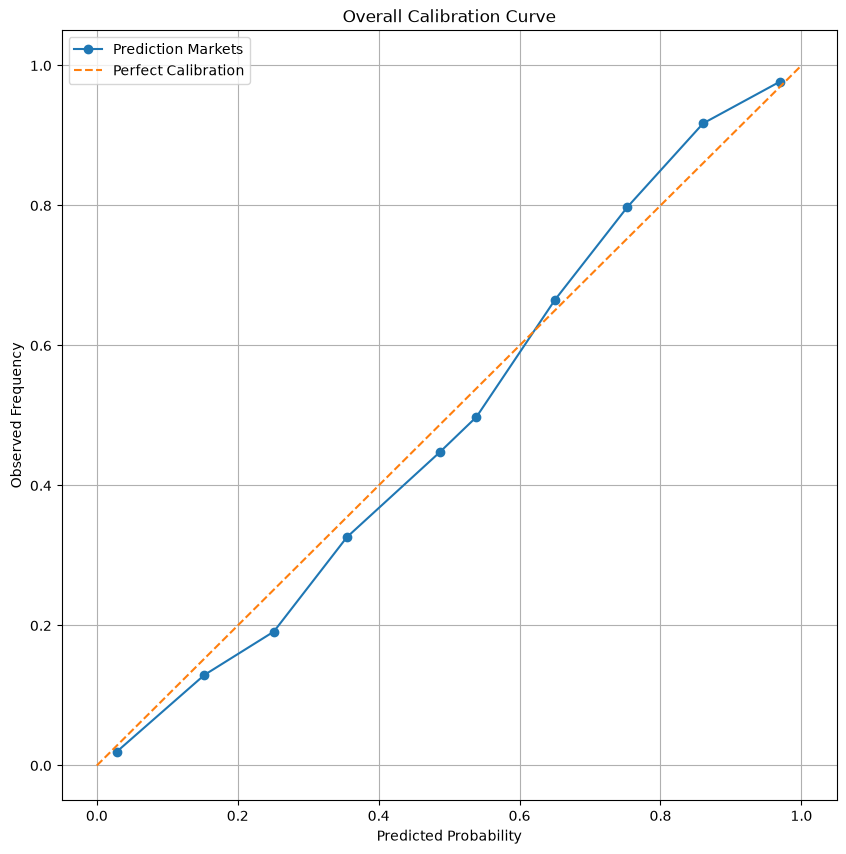

In [39]:
plt.figure(figsize=(10, 10))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Prediction Markets"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Predicted Probability")
plt.ylabel("Observed Frequency")
plt.title("Overall Calibration Curve")
plt.legend()
plt.grid()

plt.show()

In [40]:
# 10% probability bins, np.arange create 1d array 0 to 1 with interval 0.1 
bins = np.arange(0, 1.1, 0.1)

combined_clean["price_bin"] = pd.cut(
    combined_clean["price"],
    bins=bins, ## put it in these ranges
    include_lowest=True
)

# Individual pricing error
combined_clean["bias"] = (
    combined_clean["price"] - combined_clean["outcome"]
)

bias_results = (
    combined_clean
    .groupby("price_bin", observed=True)
    .agg( # syntax wokrs like: make a column using outcome with the operation mean
        n_markets=("outcome", "size"),
        avg_predicted=("price", "mean"),
        actual_frequency=("outcome", "mean"),
        avg_bias=("bias", "mean")
    )
)

print(bias_results)

def bias_statistics(group):

    errors = group["bias"]

    n = len(errors)
    mean_bias = errors.mean()

    # One-sample t-test:
    # H0: mean bias = 0
    t_stat, p_value = stats.ttest_1samp(
        errors,
        popmean=0
    )

    # 95% confidence interval
    sem = stats.sem(errors)

    ci_low, ci_high = stats.t.interval(
        confidence=0.95,
        df=n - 1,
        loc=mean_bias,
        scale=sem
    )

    return pd.Series({
        "n_markets": n,
        "avg_predicted": group["price"].mean(),
        "actual_frequency": group["outcome"].mean(),
        "bias": mean_bias,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "t_stat": t_stat,
        "p_value": p_value
    })


formal_bias = (
    combined_clean
    .groupby("price_bin", observed=True)
    .apply(
        bias_statistics,
        include_groups=False
    )
)

print(formal_bias)

               n_markets  avg_predicted  actual_frequency  avg_bias
price_bin                                                          
(-0.001, 0.1]      20570       0.028381          0.019786  0.008595
(0.1, 0.2]          6399       0.152712          0.129395  0.023317
(0.2, 0.3]          9079       0.251250          0.191321  0.059929
(0.3, 0.4]          6003       0.354918          0.326170  0.028747
(0.4, 0.5]         27475       0.486645          0.447498  0.039147
(0.5, 0.6]          5748       0.538761          0.497912  0.040849
(0.6, 0.7]          2635       0.650293          0.665275 -0.014983
(0.7, 0.8]          2211       0.753065          0.797829 -0.044764
(0.8, 0.9]          2008       0.860553          0.917331 -0.056778
(0.9, 1.0]          2639       0.969485          0.976885 -0.007400
               n_markets  avg_predicted  actual_frequency      bias    ci_low  \
price_bin                                                                       
(-0.001, 0.1]    20570

In [41]:
# bias by venue:

venue_bias = (
    combined_clean
    .groupby(
        ["venue", "price_bin"],
        observed=True
    )
    .apply(
        bias_statistics,
        include_groups=False
    )
)

print(venue_bias)


                          n_markets  avg_predicted  actual_frequency  \
venue      price_bin                                                   
Kalshi     (-0.001, 0.1]     5188.0       0.045250          0.035852   
           (0.1, 0.2]        2412.0       0.152475          0.109867   
           (0.2, 0.3]        2934.0       0.244141          0.127471   
           (0.3, 0.4]        2329.0       0.361604          0.294547   
           (0.4, 0.5]        4783.0       0.468873          0.399122   
           (0.5, 0.6]        1421.0       0.544937          0.551020   
           (0.6, 0.7]        1020.0       0.650162          0.706863   
           (0.7, 0.8]         949.0       0.755032          0.878820   
           (0.8, 0.9]        1057.0       0.870156          0.975402   
           (0.9, 1.0]         669.0       0.971779          0.986547   
Polymarket (-0.001, 0.1]    15382.0       0.022692          0.014367   
           (0.1, 0.2]        3987.0       0.152855          0.14

In [42]:

category_bias = (
    combined_clean
    .groupby(
        ["category", "price_bin"],
        observed=True
    )
    .apply(
        bias_statistics,
        include_groups=False
    )
)

print(category_bias)

                               n_markets  avg_predicted  actual_frequency  \
category        price_bin                                                   
Climate/Weather (-0.001, 0.1]      549.0       0.038578          0.025501   
                (0.1, 0.2]         258.0       0.150043          0.100775   
                (0.2, 0.3]         668.0       0.259587          0.143713   
                (0.3, 0.4]         269.0       0.345550          0.312268   
                (0.4, 0.5]         445.0       0.489022          0.166292   
...                                  ...            ...               ...   
Sports          (0.5, 0.6]        4586.0       0.537982          0.518099   
                (0.6, 0.7]        1811.0       0.648468          0.680287   
                (0.7, 0.8]        1145.0       0.749428          0.774672   
                (0.8, 0.9]         504.0       0.846306          0.892857   
                (0.9, 1.0]         331.0       0.946742          0.954683   

In [56]:
# PURGED chronological train/test split

# Order markets by when we would actually ENTER the trade
backtest_df = (
    combined_clean
    .sort_values("entry_time")
    .reset_index(drop=True)
)

# 70% point based on entry time
split_index = int(len(backtest_df) * 0.70)
split_time = backtest_df.iloc[split_index]["entry_time"]

# TRAIN:
# Only markets whose outcomes were already known before testing begins
train_df = backtest_df[
    backtest_df["resolution_date"] < split_time
].copy()

# TEST:
# Only trades entered at or after the cutoff
test_df = backtest_df[
    backtest_df["entry_time"] >= split_time
].copy()

print("Training markets:", len(train_df))
print("Testing markets:", len(test_df))

print("\nLatest known training outcome:")
print(train_df["resolution_date"].max())

print("\nFirst test entry:")
print(test_df["entry_time"].min())


# 10% probability bins
bins = np.arange(0, 1.1, 0.1)

train_df["price_bin"] = pd.cut(
    train_df["price"],
    bins=bins,
    include_lowest=True
)

test_df["price_bin"] = pd.cut(
    test_df["price"],
    bins=bins,
    include_lowest=True
)


# Learn calibration ONLY from past data
calibration_map = (
    train_df
    .groupby(
        "price_bin",
        observed=True
    )["outcome"]
    .mean()
)

print("\nTraining calibration map:")
print(calibration_map)


# Apply past calibration to future test markets
test_df["p_model"] = (
    test_df["price_bin"]
    .map(calibration_map)
    .astype(float)
)

print("\nMissing model probabilities:")
print(test_df["p_model"].isna().sum())

Training markets: 58949
Testing markets: 25468

Latest known training outcome:
2025-11-26 18:25:47+00:00

First test entry:
2025-11-26 21:00:00+00:00

Training calibration map:
price_bin
(-0.001, 0.1]    0.015388
(0.1, 0.2]       0.142782
(0.2, 0.3]       0.220280
(0.3, 0.4]       0.345433
(0.4, 0.5]       0.457531
(0.5, 0.6]       0.474359
(0.6, 0.7]       0.638633
(0.7, 0.8]       0.729254
(0.8, 0.9]       0.850333
(0.9, 1.0]       0.972737
Name: outcome, dtype: float64

Missing model probabilities:
0


In [74]:
def run_kelly_backtest(
    data,
    k=0.25,
    spread=0.02,
    starting_bankroll=10000
):

    df = (
        data
        .sort_values("entry_time")
        .copy()
    )

    half_spread = spread / 2

    cash = starting_bankroll
    locked_capital = 0

    open_positions = []

    side_history = pd.Series("NONE", index=df.index)
    fraction_history = pd.Series(0.0, index=df.index)
    pnl_history = pd.Series(0.0, index=df.index)

    equity_times = []
    equity_values = []

    # Function to settle positions that have finished
    def settle_positions(up_to_time):

        nonlocal cash
        nonlocal locked_capital
        nonlocal open_positions

        still_open = []

        for position in open_positions:

            if position["resolution_date"] <= up_to_time:

                stake = position["stake"]

                locked_capital -= stake

                if position["won"]:

                    payout = (
                        stake
                        / position["execution_price"]
                    )

                    pnl = payout - stake
                    cash += payout

                else:

                    pnl = -stake

                pnl_history.loc[
                    position["idx"]
                ] = pnl

            else:

                still_open.append(position)

        open_positions = still_open

    # Process all markets sharing the same entry time together
    for entry_time, group in df.groupby(
        "entry_time",
        sort=True
    ):

        # First settle anything that finished before now
        settle_positions(entry_time)

        # Current book-value equity
        equity = cash + locked_capital

        proposed_trades = []

        for idx, row in group.iterrows():

            p_market = row["price"]
            p_model = row["p_model"]

            yes_price = (
                p_market + half_spread
            )

            no_price = (
                1 - p_market + half_spread
            )

            kelly_yes = 0
            kelly_no = 0

            if 0 < yes_price < 1:

                kelly_yes = max(
                    (
                        p_model
                        - yes_price
                    )
                    /
                    (
                        1 - yes_price
                    ),
                    0
                )

            if 0 < no_price < 1:

                kelly_no = max(
                    (
                        (1 - p_model)
                        - no_price
                    )
                    /
                    (
                        1 - no_price
                    ),
                    0
                )

            if kelly_yes > 0:

                side = "YES"
                full_kelly = kelly_yes
                execution_price = yes_price
                won = row["outcome"] == 1

            elif kelly_no > 0:

                side = "NO"
                full_kelly = kelly_no
                execution_price = no_price
                won = row["outcome"] == 0

            else:

                side = "NONE"
                full_kelly = 0
                execution_price = np.nan
                won = False

            fraction = (
                k * full_kelly
            )

            desired_stake = (
                equity * fraction
            )

            proposed_trades.append(
                {
                    "idx": idx,
                    "side": side,
                    "fraction": fraction,
                    "desired_stake": desired_stake,
                    "execution_price": execution_price,
                    "won": won,
                    "resolution_date":
                        row["resolution_date"]
                }
            )

        # Don't spend more cash than we actually have
        total_desired = sum(
            trade["desired_stake"]
            for trade in proposed_trades
        )

        if (
            total_desired > cash
            and total_desired > 0
        ):

            scale = (
                cash / total_desired
            )

        else:

            scale = 1

        # Open all positions for this entry timestamp
        for trade in proposed_trades:

            idx = trade["idx"]


            stake = (
                trade["desired_stake"]
                * scale
            )

            if trade["side"] == "NONE" or stake <= 0:
                continue

            side_history.loc[idx] = trade["side"]

            fraction_history.loc[idx] = (
                trade["fraction"] * scale
            )

            cash -= stake
            locked_capital += stake

            open_positions.append(
                {
                    "idx": idx,
                    "stake": stake,
                    "execution_price":
                        trade["execution_price"],
                    "won": trade["won"],
                    "resolution_date":
                        trade["resolution_date"]
                }
            )

        equity_times.append(entry_time)

        equity_values.append(
            cash + locked_capital
        )

    # Settle everything remaining
    final_time = (
        df["resolution_date"].max()
        + pd.Timedelta(seconds=1)
    )

    settle_positions(final_time)

    equity_times.append(final_time)
    equity_values.append(cash)

    final_bankroll = cash

    total_return = (
        final_bankroll
        / starting_bankroll
    ) - 1

    # Equity curve
    equity_curve = pd.Series(
        equity_values,
        index=pd.to_datetime(
            equity_times,
            utc=True
        )
    )

    running_peak = (
        equity_curve.cummax()
    )

    drawdowns = (
        equity_curve
        / running_peak
    ) - 1

    max_drawdown = (
        -drawdowns.min()
    )

    # Daily Sharpe
    daily_equity = (
        equity_curve
        .resample("1D")
        .last()
        .ffill()
    )

    daily_returns = (
        daily_equity
        .pct_change(fill_method=None)
        .dropna()
    )

    if (
        len(daily_returns) > 1
        and daily_returns.std() > 0
    ):

        sharpe = (
            daily_returns.mean()
            / daily_returns.std()
        ) * np.sqrt(365)

    else:

        sharpe = np.nan

    df["backtest_side"] = side_history
    df["bet_fraction"] = fraction_history
    df["pnl"] = pnl_history

    metrics = {
        "k": k,
        "spread": spread,
        "starting_bankroll":
            starting_bankroll,
        "final_bankroll":
            final_bankroll,
        "total_return":
            total_return,
        "sharpe":
            sharpe,
        "max_drawdown":
            max_drawdown,
        "trades":
            (
                df["backtest_side"]
                != "NONE"
            ).sum()
    }

    return df, metrics, equity_curve

In [75]:
no_cost_df, no_cost_metrics, no_cost_equity = (
    run_kelly_backtest(
        test_df,
        k=0.25,
        spread=0.00
    )
)

cost_df, cost_metrics, cost_equity = (
    run_kelly_backtest(
        test_df,
        k=0.25,
        spread=0.02
    )
)

comparison = pd.DataFrame(
    [
        no_cost_metrics,
        cost_metrics
    ],
    index=[
        "No transaction costs",
        "2-cent spread"
    ]
)

print(
    comparison[
        [
            "final_bankroll",
            "total_return",
            "sharpe",
            "max_drawdown",
            "trades"
        ]
    ]
)

                      final_bankroll  total_return    sharpe  max_drawdown  \
No transaction costs     5384.229819     -0.461577 -0.337840      0.606876   
2-cent spread            6113.712293     -0.388629 -1.109007      0.474378   

                      trades  
No transaction costs    6069  
2-cent spread           5135  


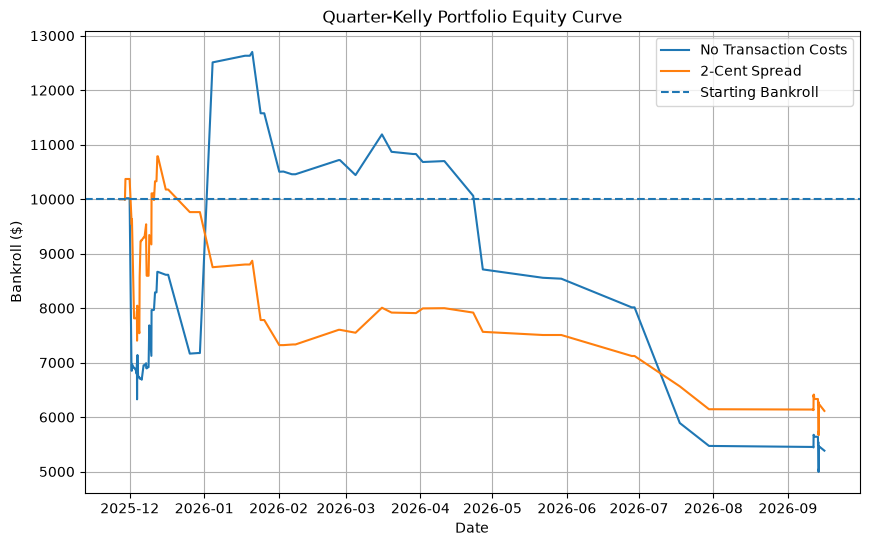

In [76]:
plt.figure(figsize=(10, 6))

plt.plot(
    no_cost_equity.index,
    no_cost_equity.values,
    label="No Transaction Costs"
)

plt.plot(
    cost_equity.index,
    cost_equity.values,
    label="2-Cent Spread"
)

plt.axhline(
    10000,
    linestyle="--",
    label="Starting Bankroll"
)

plt.xlabel("Date")
plt.ylabel("Bankroll ($)")
plt.title("Quarter-Kelly Portfolio Equity Curve")
plt.legend()
plt.grid()
plt.show()

In [77]:
k_values = np.arange(0.1, 1.01, 0.1)

sensitivity_results = []

for k in k_values:

    _, metrics, _ = run_kelly_backtest(
        test_df,
        k=k,
        spread=0.02
    )

    sensitivity_results.append(metrics)

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

print(
    sensitivity_df[
        [
            "k",
            "final_bankroll",
            "total_return",
            "sharpe",
            "max_drawdown",
            "trades"
        ]
    ]
)

     k  final_bankroll  total_return    sharpe  max_drawdown  trades
0  0.1     8134.577178     -0.186542 -0.846667      0.317884    5418
1  0.2     7051.040186     -0.294896 -1.013672      0.447096    5363
2  0.3     4874.182800     -0.512582 -1.634947      0.563335    5006
3  0.4     4364.082412     -0.563592 -2.039850      0.608532    4993
4  0.5     4720.548879     -0.527945 -1.583426      0.550883    4696
5  0.6     5063.471602     -0.493653 -1.098460      0.599596    4488
6  0.7     5076.292760     -0.492371 -0.868831      0.648960    4430
7  0.8     4818.378776     -0.518162 -0.777358      0.699039    4181
8  0.9     4398.144654     -0.560186 -0.739538      0.745275    4206
9  1.0     4049.587927     -0.595041 -0.688914      0.784204    4134


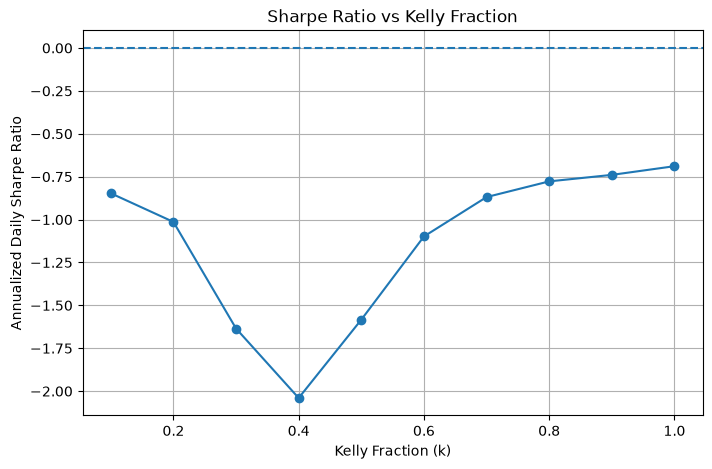

In [78]:
plt.figure(figsize=(8, 5))

plt.plot(
    sensitivity_df["k"],
    sensitivity_df["sharpe"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Kelly Fraction (k)")
plt.ylabel("Annualized Daily Sharpe Ratio")
plt.title("Sharpe Ratio vs Kelly Fraction")

plt.grid()
plt.show()

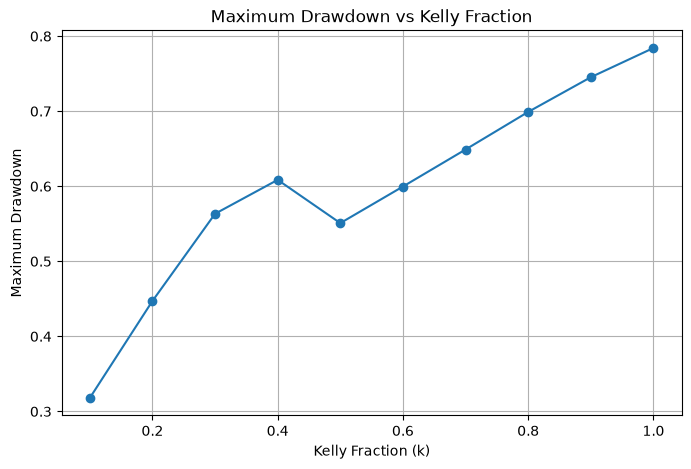

In [79]:
plt.figure(figsize=(8, 5))

plt.plot(
    sensitivity_df["k"],
    sensitivity_df["max_drawdown"],
    marker="o"
)

plt.xlabel("Kelly Fraction (k)")
plt.ylabel("Maximum Drawdown")
plt.title("Maximum Drawdown vs Kelly Fraction")

plt.grid()
plt.show()

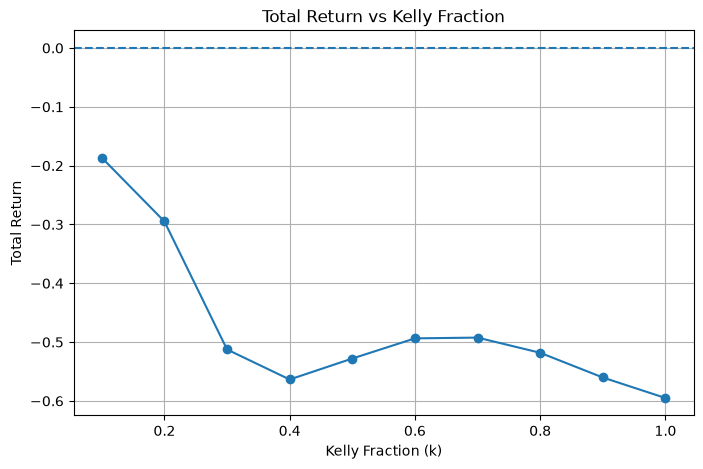

In [80]:
plt.figure(figsize=(8, 5))

plt.plot(
    sensitivity_df["k"],
    sensitivity_df["total_return"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Kelly Fraction (k)")
plt.ylabel("Total Return")
plt.title("Total Return vs Kelly Fraction")

plt.grid()
plt.show()

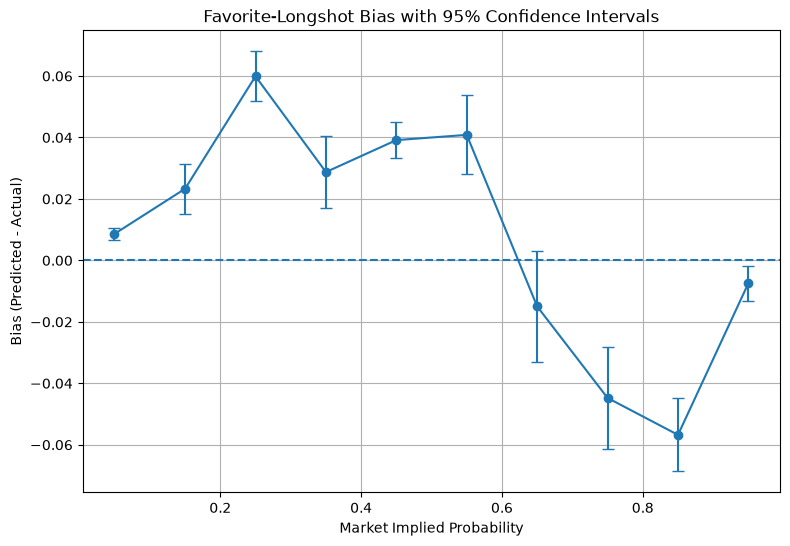

In [81]:
bias_plot = formal_bias.reset_index()

bias_plot["bin_midpoint"] = (
    bias_plot["price_bin"]
    .apply(lambda x: x.mid)
    .astype(float)
)

lower_error = (
    bias_plot["bias"] - bias_plot["ci_low"]
)

upper_error = (
    bias_plot["ci_high"] - bias_plot["bias"]
)

plt.figure(figsize=(9, 6))

plt.errorbar(
    bias_plot["bin_midpoint"],
    bias_plot["bias"],
    yerr=[lower_error, upper_error],
    marker="o",
    capsize=4
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Market Implied Probability")
plt.ylabel("Bias (Predicted - Actual)")
plt.title(
    "Favorite-Longshot Bias with 95% Confidence Intervals"
)

plt.grid()
plt.show()

In [82]:
summary_stats = (
    combined_clean
    .groupby(["venue", "category"])
    .agg(
        n_contracts=("outcome", "size"),
        resolution_rate=("outcome", "mean"),
        mean_implied_probability=("price", "mean")
    )
)

print(summary_stats)

                               n_contracts  resolution_rate  \
venue      category                                           
Kalshi     Climate/Weather             125         0.272000   
           Commodities                 240         0.370833   
           Economics/Finance          3483         0.519093   
           Entertainment               202         0.247525   
           Other                       120         0.416667   
           Science/Technology           20         0.300000   
           Sports                    18572         0.291406   
Polymarket Climate/Weather            2232         0.144713   
           Crypto                    22576         0.397679   
           Economics/Finance          1110         0.309910   
           Entertainment              1132         0.236749   
           Other                      8666         0.137434   
           Politics                   3198         0.301438   
           Science/Technology          636         0.14

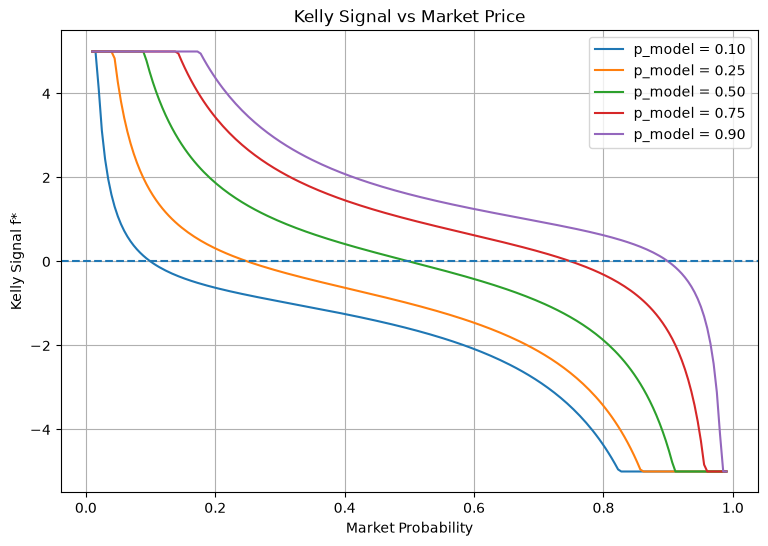

In [83]:
market_prices = np.linspace(0.01, 0.99, 200)

model_probabilities = [
    0.10,
    0.25,
    0.50,
    0.75,
    0.90
]

plt.figure(figsize=(9, 6))

for p_model_value in model_probabilities:

    kelly_signal = (
        (p_model_value - market_prices)
        /
        (
            market_prices
            * (1 - market_prices)
        )
    )

    kelly_signal = np.clip(
        kelly_signal,
        -5,
        5
    )

    plt.plot(
        market_prices,
        kelly_signal,
        label=f"p_model = {p_model_value:.2f}"
    )

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Market Probability")
plt.ylabel("Kelly Signal f*")
plt.title("Kelly Signal vs Market Price")

plt.legend()
plt.grid()
plt.show()

In [84]:
import os

os.makedirs("../outputs", exist_ok=True)

summary_stats.to_csv(
    "../outputs/summary_statistics.csv"
)

formal_bias.to_csv(
    "../outputs/favorite_longshot_bias.csv"
)

venue_bias.to_csv(
    "../outputs/venue_bias.csv"
)

sensitivity_df.to_csv(
    "../outputs/kelly_sensitivity.csv",
    index=False
)

comparison.to_csv(
    "../outputs/backtest_comparison.csv"
)

if "category_bias" in globals():
    category_bias.to_csv(
        "../outputs/category_bias.csv"
    )


In [88]:
# Final Data check
print("Markets:", len(combined_clean))
print("\nBy venue:")
print(combined_clean["venue"].value_counts())

print(
    "\nMissing entry times:",
    combined_clean["entry_time"].isna().sum()
)

print(
    "Bad entry times:",
    (
        combined_clean["entry_time"]
        >= combined_clean["resolution_date"]
    ).sum()
)

print("\nBACKTEST CHECK")
print("Training:", len(train_df))
print("Testing:", len(test_df))
print("Missing p_model:", test_df["p_model"].isna().sum())

print("\nBACKTEST RESULTS")
print(
    comparison[
        [
            "final_bankroll",
            "total_return",
            "sharpe",
            "max_drawdown",
            "trades"
        ]
    ]
)

print("\nKELLY SENSITIVITY")
print(sensitivity_df)

Markets: 84767

By venue:
venue
Polymarket    62005
Kalshi        22762
Name: count, dtype: int64

Missing entry times: 0
Bad entry times: 0

BACKTEST CHECK
Training: 58949
Testing: 25468
Missing p_model: 0

BACKTEST RESULTS
                      final_bankroll  total_return    sharpe  max_drawdown  \
No transaction costs     5384.229819     -0.461577 -0.337840      0.606876   
2-cent spread            6113.712293     -0.388629 -1.109007      0.474378   

                      trades  
No transaction costs    6069  
2-cent spread           5135  

KELLY SENSITIVITY
     k  spread  starting_bankroll  final_bankroll  total_return    sharpe  \
0  0.1    0.02              10000     8134.577178     -0.186542 -0.846667   
1  0.2    0.02              10000     7051.040186     -0.294896 -1.013672   
2  0.3    0.02              10000     4874.182800     -0.512582 -1.634947   
3  0.4    0.02              10000     4364.082412     -0.563592 -2.039850   
4  0.5    0.02              10000     4720.

In [89]:
def brier_vs_naive(df):
    market = brier_score_loss(
        df["outcome"],
        df["price"]
    )

    base_rate = df["outcome"].mean()

    naive = brier_score_loss(
        df["outcome"],
        np.full(len(df), base_rate)
    )

    return pd.Series({
        "market_brier": market,
        "naive_brier": naive
    })


print("Brier vs Naive by Venue")
print(
    combined_clean
    .groupby("venue")
    .apply(
        brier_vs_naive,
        include_groups=False
    )
)

print("\nBrier vs Naive by Category")
print(
    combined_clean
    .groupby("category")
    .apply(
        brier_vs_naive,
        include_groups=False
    )
)

Brier vs Naive by Venue
            market_brier  naive_brier
venue                                
Kalshi          0.139037     0.220159
Polymarket      0.162964     0.221718

Brier vs Naive by Category
                    market_brier  naive_brier
category                                     
Climate/Weather         0.141729     0.128522
Commodities             0.111697     0.233316
Crypto                  0.177527     0.239530
Economics/Finance       0.066086     0.249010
Entertainment           0.092020     0.181555
Other                   0.080758     0.121297
Politics                0.106125     0.210573
Science/Technology      0.041202     0.129201
Sports                  0.180329     0.223422
